In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Step 1: Problem statement

The objective of this project is to develop a machine learning classification system that predicts agricultural risk levels based on environmental conditions, soil properties, crop health, and other available agricultural indicators. The system will help farmers and agricultural advisors identify potentially risky farming conditions and prioritize further investigation.

Model's predictions are decision-support estimates, not guaranteed predictions of crop failure or financial loss.

### Step 2: Data collection and EDA

In [3]:
df = pd.read_csv("modern_agriculture_ai_crop_production_2020_2050.csv")

In [4]:
df.head()

,record_id,year,region,country,crop,farm_size_hectares,farm_type,soil_type,irrigation_type,ai_system_used,...,production_tons,operational_cost_usd_per_ha,market_price_usd_per_ton,revenue_usd,profit_usd,carbon_emission_kgco2e_per_ha,sustainability_score,yield_forecast_next_year_ton_per_ha,risk_category,recommended_action
0,1,2035,South America,Chile,Dates,40.78,Semi-Mechanized,Peaty,Rainfed,NaN,...,330.32,1059.23,196.12,64782.36,21586.96,646.75,54.25,8.38,Moderate,Start with IoT soil sensors and basic AI analy...
1,2,2038,Middle East,Turkey,Potato,17.04,Traditional,Silty,Smart Drip,NaN,...,422.59,1017.69,442.65,187059.46,169718.02,948.05,28.77,24.56,Moderate,Start with IoT soil sensors and basic AI analy...
2,3,2036,Africa,Egypt,Mango,119.06,Smart AI Farm,Loam,Drip,AI Irrigation Agent,...,1382.29,1479.36,463.90,641244.33,465111.73,1062.54,57.07,11.81,Moderate,Maintain current smart farming plan
3,4,2031,Europe,Germany,Rice,23.15,Semi-Mechanized,Silty,Flood Irrigation,Yield Prediction ML,...,126.86,1088.85,375.24,47602.95,22396.07,672.48,54.67,5.60,Moderate,Shift to drip or smart irrigation
4,5,2029,South America,Colombia,Sugarcane,22.03,Semi-Mechanized,Silty,Drip,Basic Analytics,...,1441.42,870.99,198.97,286799.34,267611.43,516.42,44.15,72.07,Moderate,Deploy pest monitoring traps and precision spr...


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 75000
Total Columns: 36


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 36 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   record_id                            75000 non-null  int64  
 1   year                                 75000 non-null  int64  
 2   region                               75000 non-null  str    
 3   country                              75000 non-null  str    
 4   crop                                 75000 non-null  str    
 5   farm_size_hectares                   75000 non-null  float64
 6   farm_type                            75000 non-null  str    
 7   soil_type                            75000 non-null  str    
 8   irrigation_type                      75000 non-null  str    
 9   ai_system_used                       60019 non-null  str    
 10  technology_stack                     75000 non-null  str    
 11  ai_adoption_score                    75

In [7]:
print("\nNUMERIC COLUMNS")
print(df.select_dtypes(include=np.number).columns.tolist())


NUMERIC COLUMNS
['record_id', 'year', 'farm_size_hectares', 'ai_adoption_score', 'mechanization_index', 'iot_sensor_density_per_ha', 'drone_usage_hours_per_month', 'satellite_monitoring_score', 'avg_temperature_c', 'annual_rainfall_mm', 'soil_moisture_percent', 'fertilizer_kg_per_ha', 'pesticide_litre_per_ha', 'water_use_m3_per_ha', 'climate_stress_index', 'disease_risk_score', 'pest_risk_score', 'yield_ton_per_ha', 'production_tons', 'operational_cost_usd_per_ha', 'market_price_usd_per_ton', 'revenue_usd', 'profit_usd', 'carbon_emission_kgco2e_per_ha', 'sustainability_score', 'yield_forecast_next_year_ton_per_ha']


In [8]:
print("\nCATEGORICAL COLUMNS")
print(df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist())


CATEGORICAL COLUMNS
['region', 'country', 'crop', 'farm_type', 'soil_type', 'irrigation_type', 'ai_system_used', 'technology_stack', 'risk_category', 'recommended_action']


In [9]:
print("\nMISSING VALUES")
print(df.isnull().sum()[df.isnull().sum() > 0])


MISSING VALUES
ai_system_used    14981
dtype: int64


In [10]:
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


DUPLICATE ROWS
0


In [11]:
print("\nNUMERIC STATISTICAL SUMMARY")
print(df.describe().T)


NUMERIC STATISTICAL SUMMARY
                                       count           mean            std  \
record_id                            75000.0   37500.500000   21650.779432   
year                                 75000.0    2034.956960       8.927437   
farm_size_hectares                   75000.0      26.904183      17.763317   
ai_adoption_score                    75000.0      52.687583      20.301630   
mechanization_index                  75000.0      50.005910      16.480170   
iot_sensor_density_per_ha            75000.0       7.879769       5.201213   
drone_usage_hours_per_month          75000.0       4.088757       4.101138   
satellite_monitoring_score           75000.0      48.573390      23.954710   
avg_temperature_c                    75000.0      27.003973       5.503631   
annual_rainfall_mm                   75000.0     651.015669     275.632315   
soil_moisture_percent                75000.0      36.827855      11.187087   
fertilizer_kg_per_ha               

In [12]:
print("\nCATEGORICAL UNIQUE VALUES")

for col in df.select_dtypes(include=['object', 'category', 'bool']).columns:
    print(col, ":", df[col].nunique())


CATEGORICAL UNIQUE VALUES
region : 9
country : 36
crop : 10
farm_type : 6
soil_type : 6
irrigation_type : 6
ai_system_used : 6
technology_stack : 7
risk_category : 4
recommended_action : 6


In [13]:
print("\nTARGET CLASS DISTRIBUTION")
print(df['risk_category'].value_counts())


TARGET CLASS DISTRIBUTION
risk_category
Moderate    59056
High        12754
Low          3070
Critical      120
Name: count, dtype: int64


In [14]:
features=['avg_temperature_c','annual_rainfall_mm','soil_moisture_percent','fertilizer_kg_per_ha','pesticide_litre_per_ha','climate_stress_index','disease_risk_score','pest_risk_score','yield_ton_per_ha']

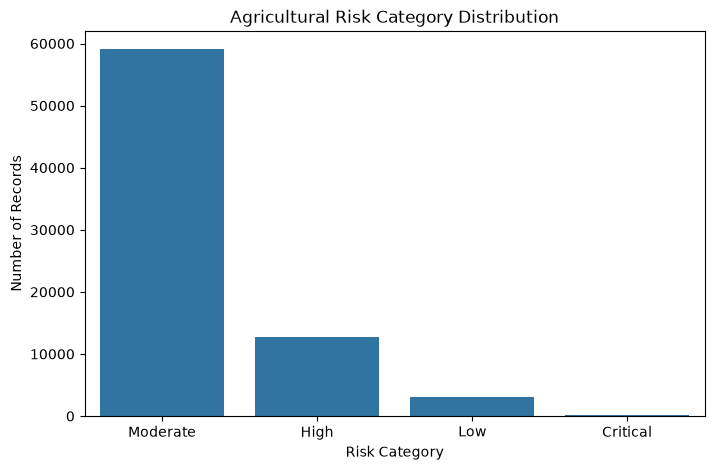

In [15]:
#Risk category distribution - Shows the distribution of Low, Moderate, High, and Critical risk classes.

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='risk_category',
              order=df['risk_category'].value_counts().index)

plt.title('Agricultural Risk Category Distribution')
plt.xlabel('Risk Category')
plt.ylabel('Number of Records')
plt.show()

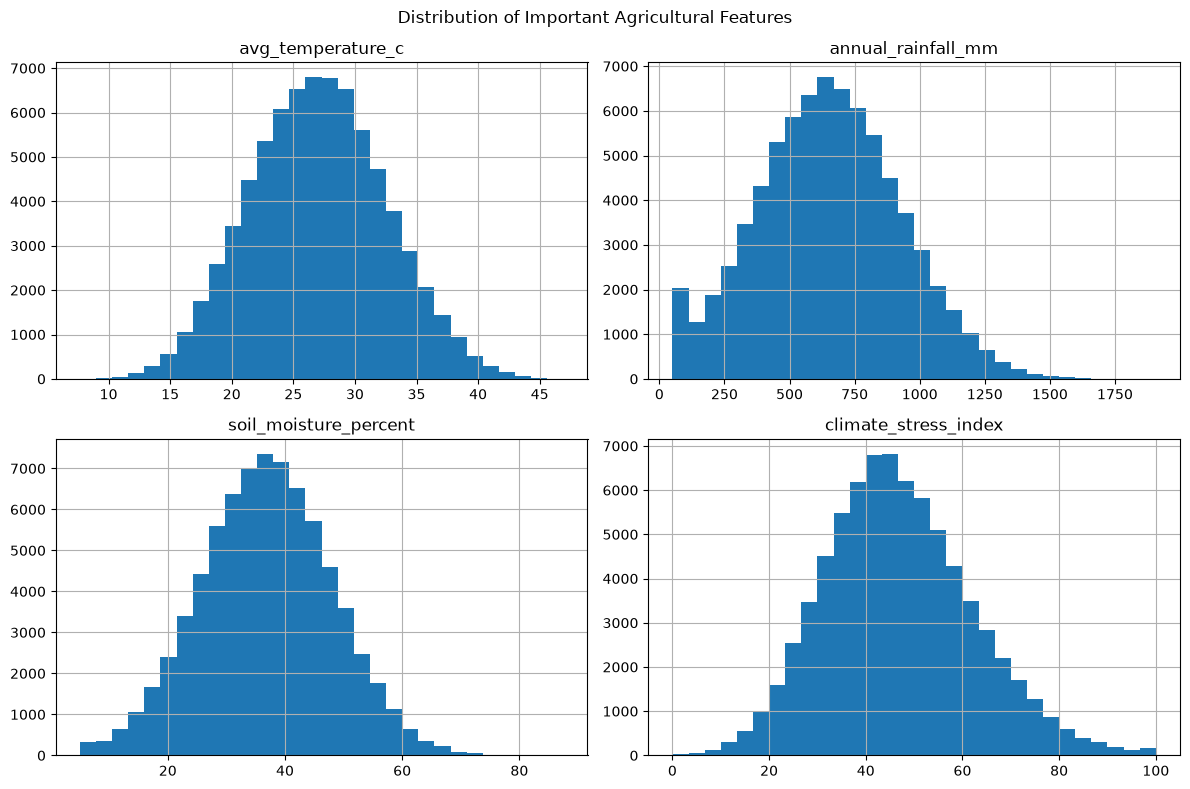

In [16]:
#Numerical feature distributions - Use only four important agricultural features instead of plotting every numerical column.

features = [
    'avg_temperature_c',
    'annual_rainfall_mm',
    'soil_moisture_percent',
    'climate_stress_index'
]

df[features].hist(figsize=(12, 8), bins=30)

plt.suptitle('Distribution of Important Agricultural Features')
plt.tight_layout()
plt.show()

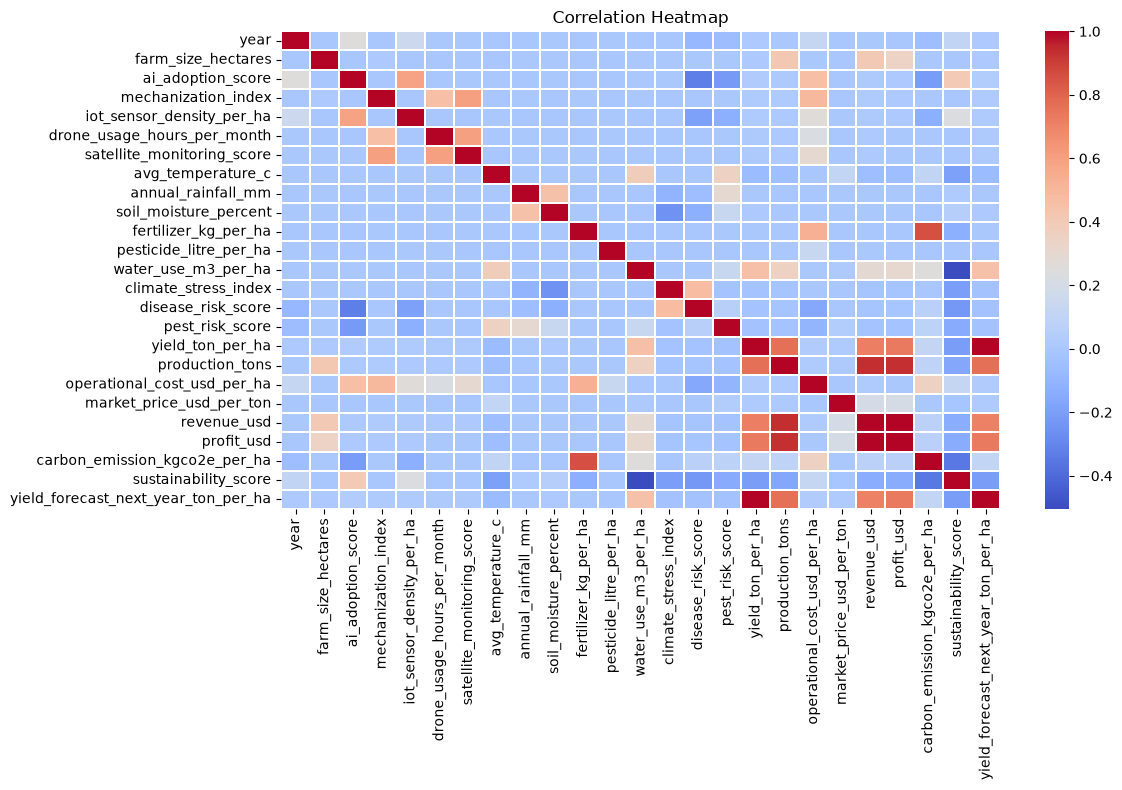

In [17]:
#Correlation heatmap - Shows relationships between numerical features.

numeric_df = df.select_dtypes(include=np.number)

# Remove identifier
numeric_df = numeric_df.drop(columns=['record_id'], errors='ignore')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    cmap='coolwarm',
    annot=False,
    linewidths=0.3
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

### Step 3: Preprocessing and feature engineering

In [18]:
X = df.drop(columns=["risk_category", "recommended_action"])
y = df["risk_category"]

In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 34)
Testing data: (15000, 34)


In [20]:
numeric_columns = X_train.select_dtypes(include=["int64", "float64"]).columns

categorical_columns = X_train.select_dtypes(include=["object"]).columns

print("Numerical columns:", list(numeric_columns))
print("Categorical columns:", list(categorical_columns))

Numerical columns: ['record_id', 'year', 'farm_size_hectares', 'ai_adoption_score', 'mechanization_index', 'iot_sensor_density_per_ha', 'drone_usage_hours_per_month', 'satellite_monitoring_score', 'avg_temperature_c', 'annual_rainfall_mm', 'soil_moisture_percent', 'fertilizer_kg_per_ha', 'pesticide_litre_per_ha', 'water_use_m3_per_ha', 'climate_stress_index', 'disease_risk_score', 'pest_risk_score', 'yield_ton_per_ha', 'production_tons', 'operational_cost_usd_per_ha', 'market_price_usd_per_ton', 'revenue_usd', 'profit_usd', 'carbon_emission_kgco2e_per_ha', 'sustainability_score', 'yield_forecast_next_year_ton_per_ha']
Categorical columns: ['region', 'country', 'crop', 'farm_type', 'soil_type', 'irrigation_type', 'ai_system_used', 'technology_stack']


In [21]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Separate numerical and categorical columns
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include="object").columns

# Fill missing numerical values with median
num_imputer = SimpleImputer(strategy="median")
X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

# Fill missing categorical values with most frequent value
cat_imputer = SimpleImputer(strategy="most_frequent")
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

# Encode categorical columns
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# Make train and test columns match
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Scale numerical features
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("Missing values handled, encoding and scaling completed!")

Missing values handled, encoding and scaling completed!


### Step 4: Baseline model

In [22]:
#Train the baseline model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000, class_weight="balanced")
model.fit(X_train, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [23]:
y_pred = model.predict(X_test)

In [24]:
#Evaluate the model

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9786666666666667

Classification Report:
              precision    recall  f1-score   support

    Critical       0.71      0.92      0.80        24
        High       0.94      1.00      0.97      2551
         Low       0.81      1.00      0.89       614
    Moderate       1.00      0.97      0.99     11811

    accuracy                           0.98     15000
   macro avg       0.86      0.97      0.91     15000
weighted avg       0.98      0.98      0.98     15000


Confusion Matrix:
[[   22     2     0     0]
 [    9  2542     0     0]
 [    0     0   614     0]
 [    0   162   147 11502]]


### Step 5: Model comparison 

In [25]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

In [26]:
#Compare model performance
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred
}

for name, predictions in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Macro F1:", f1_score(y_test, predictions, average="macro"))


 Logistic Regression
Accuracy: 0.9786666666666667
Macro F1: 0.9117319996825715

 Decision Tree
Accuracy: 0.9638666666666666
Macro F1: 0.8158569716805716

 Random Forest
Accuracy: 0.9406
Macro F1: 0.6847033456980351


### Step-6 : Hyperparameter tuning and cross-validation

In [28]:
#Import GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

In [29]:
#Define parameters to test

params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5]
}

In [30]:
# Preprocessing is already completed in Step 3.
# The training and testing data are ready for model tuning.
#Perform hyperparameter tuning

rf = RandomForestClassifier(random_state=42,class_weight="balanced")

In [31]:
from sklearn.model_selection import GridSearchCV

# Tune the Random Forest model using the preprocessed training data
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV Macro F1:", grid_search.best_score_)

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best CV Macro F1: 0.7029645403331182


In [32]:
#Display the best parameters

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Macro F1:", grid_search.best_score_)

Best Parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best Cross-Validation Macro F1: 0.7029645403331182


In [33]:
#Evaluate the tuned model

best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

    Critical       1.00      0.12      0.22        24
        High       0.83      0.95      0.88      2551
         Low       0.70      0.78      0.74       614
    Moderate       0.98      0.94      0.96     11811

    accuracy                           0.94     15000
   macro avg       0.88      0.70      0.70     15000
weighted avg       0.94      0.94      0.94     15000



### Step 7 : Final model evaluation and selection

In [34]:
#Evaluate the tuned model

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("Macro F1:", f1_score(y_test, y_pred_tuned, average="macro"))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Accuracy: 0.9356666666666666
Macro F1: 0.7020299111505561

Classification Report:
              precision    recall  f1-score   support

    Critical       1.00      0.12      0.22        24
        High       0.83      0.95      0.88      2551
         Low       0.70      0.78      0.74       614
    Moderate       0.98      0.94      0.96     11811

    accuracy                           0.94     15000
   macro avg       0.88      0.70      0.70     15000
weighted avg       0.94      0.94      0.94     15000


Confusion Matrix:
[[    3    21     0     0]
 [    0  2421     0   130]
 [    0     0   481   133]
 [    0   479   202 11130]]


In [35]:
#Compare all models

results = {
    "Logistic Regression": y_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Tuned Random Forest": y_pred_tuned
}

for name, predictions in results.items():
    print(
        name,
        "Macro F1:",
        f1_score(y_test, predictions, average="macro")
    )

Logistic Regression Macro F1: 0.9117319996825715
Decision Tree Macro F1: 0.8158569716805716
Random Forest Macro F1: 0.6847033456980351
Tuned Random Forest Macro F1: 0.7020299111505561


### Step 8 : Model Interpretation and Error Analysis

#### Model Interpretation

In [ ]:
#Find the important features
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate feature importance
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
})

# Sort by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

In [ ]:
#Visualize the top 10 important features

import matplotlib.pyplot as plt

top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.title("Top 10 Important Features")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

#### Error Analysis

In [ ]:
#Create an error analysis table

# Create a copy of test data
error_df = X_test.copy()

# Add actual and predicted values
error_df["Actual"] = y_test
error_df["Predicted"] = best_model.predict(X_test)

# Select incorrect predictions
errors = error_df[
    error_df["Actual"] != error_df["Predicted"]
]

print("Total incorrect predictions:", len(errors))

print(errors.head(10))

In [ ]:
#Find which risk categories are misclassified

import pandas as pd

confusion = pd.crosstab(
    errors["Actual"],
    errors["Predicted"]
)

print(confusion)

In [ ]:
#Calculate errors for each category

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    best_model.predict(X_test),
    zero_division=0
))